### Classification with K-means clustering and Hyper-parameter optimization using grid search

In [1]:
def load_csv(file_path):
    data = []
    with open(file_path, mode='r', newline='') as csvfile:
        rows = [line.strip().split(",") for line in csvfile]
    return rows

In [2]:
#asus
data = load_csv("C:\programming stuff\Masters_AI\AI_programming\lab3\inc_vs_rent.csv")
#mac
#data = load_csv("/Users/VKRISH18/personal/masters/Ai_programmin_course/lab3/inc_vs_rent.csv")

In [3]:
import pandas as pd
data_df = pd.DataFrame(data[1:], columns=data[0])
data_df.drop(columns=data_df.columns[0], inplace=True)
data_df.head(10)

,year,region,Annual rent sqm,Avg yearly inc KSEK
0,2020,01 Stockholm county,1341,350.30370370370366
1,2020,03 Uppsala county,1303,306.91604938271604
2,2020,04 Södermanland county,1129,283.75679012345677
3,2020,05 Östergötland county,1144,289.5
4,2020,06 Jönköping county,1044,287.47037037037035
5,2020,07 Kronoberg county,1040,282.4246913580247
6,2020,08 Kalmar county,1008,278.19629629629634
7,2020,09 Gotland county,1120,270.56296296296296
8,2020,10 Blekinge county,1096,282.94444444444446
9,2020,12 Skåne county,1212,294.2456790123457


In [4]:
data_df[['Annual rent sqm', 'Avg yearly inc KSEK']] = data_df[
    ['Annual rent sqm', 'Avg yearly inc KSEK']
].astype(float)


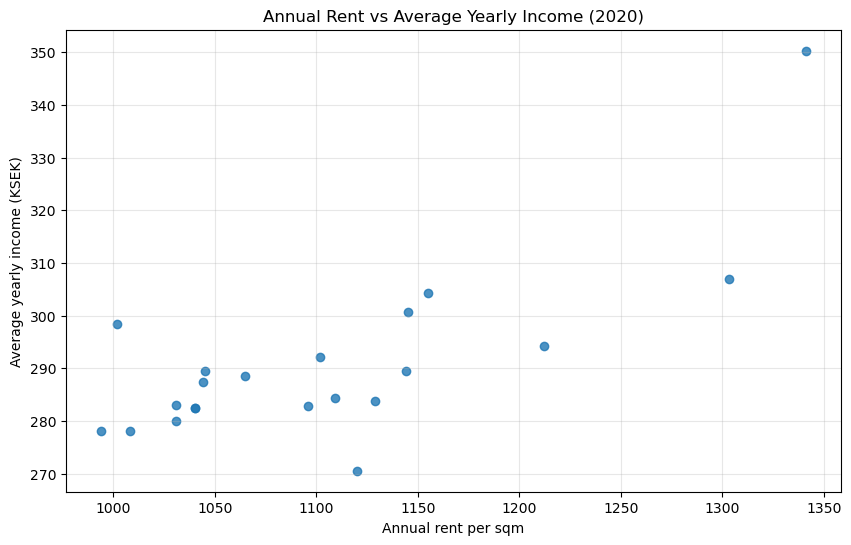

In [5]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.scatter(
    data_df['Annual rent sqm'],
    data_df['Avg yearly inc KSEK'],
    alpha=0.8
)

plt.xlabel('Annual rent per sqm')
plt.ylabel('Average yearly income (KSEK)')
plt.title('Annual Rent vs Average Yearly Income (2020)')
plt.grid(True, alpha=0.3)

plt.show()

In [19]:
type(data_df['Avg yearly inc KSEK'])

pandas.core.series.Series

In [7]:
data_df.columns

Index(['year', 'region', 'Annual rent sqm', 'Avg yearly inc KSEK'], dtype='object')

In [22]:
data_df_points = data_df[['Annual rent sqm', 'Avg yearly inc KSEK']]
data_df_points.dtypes

Annual rent sqm        float64
Avg yearly inc KSEK    float64
dtype: object

In [23]:
import numpy as np

class KMeans:
    def __init__(self, df, k, max_iters=10):
        self.__k = k                  # encapsulation (private)
        self.df = df
        self.max_iters = max_iters
        self.centroids = None
        self.labels = None            # which cluster each point belongs to

    def get_k(self):
        return self.__k

    # Step 1: initialize centroids as random points from the sample
    def initialize_centroids(self):
        if self.__k > len(self.df):
            raise ValueError("k cannot be greater than the number of data points")
        self.centroids = self.df.sample(n=self.__k).values.astype(float)

    def euclidean_distance(self, point1, point2):
        return np.linalg.norm(point1 - point2)

    # Step 2: assign every point to its closest centroid
    def assign_clusters(self):
        self.labels = []
        for p in self.df.values:
            distances = [self.euclidean_distance(p, c) for c in self.centroids]
            self.labels.append(np.argmin(distances))
        self.labels = np.array(self.labels)
        return self.labels

    # Step 3: new centroid = mean of the points in each cluster
    def calc_centroids(self):
        new_centroids = self.centroids.copy()
        for i in range(self.__k):
            points = self.df.values[self.labels == i]
            if len(points) > 0:       # keep the old centroid if a cluster is empty
                new_centroids[i] = np.mean(points, axis=0)
        return new_centroids

    # Step 4: repeat for up to N iterations, stopping early once centroids stop changing
    def fit(self):
        self.initialize_centroids()
        for i in range(self.max_iters):
            self.assign_clusters()
            new_centroids = self.calc_centroids()
            if np.allclose(new_centroids, self.centroids):
                print(f"Converged after {i + 1} iterations")
                break
            self.centroids = new_centroids
        return self.labels, self.centroids


In [24]:
data_df_points.sample(3).values.astype(float)

array([[1303.        ,  306.91604938],
       [1341.        ,  350.3037037 ],
       [1144.        ,  289.5       ]])

In [25]:
model = KMeans(data_df_points,k=3,max_iters=10)
lables, centroids = model.fit()

Converged after 7 iterations


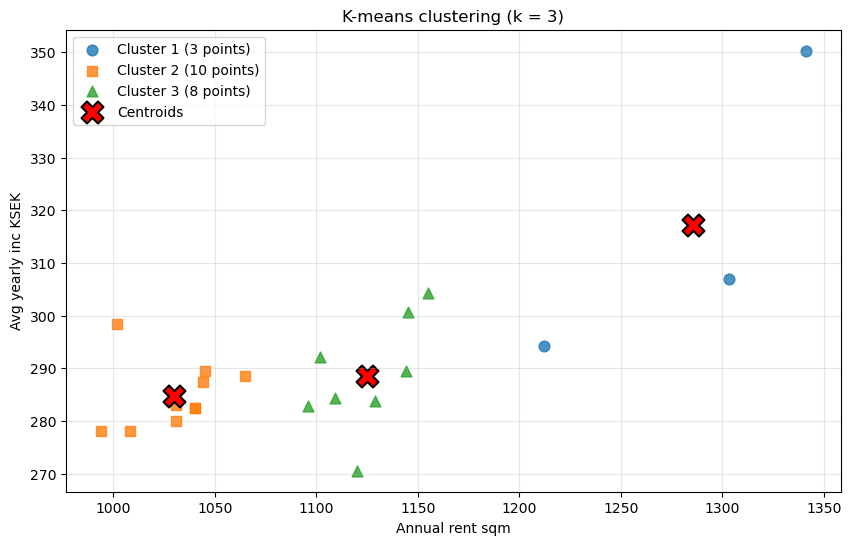

In [ ]:

k = model.get_k()
x_column, y_column = data_df_points.columns
colors = ['tab:blue', 'tab:orange', 'tab:green', 'tab:purple', 'tab:brown']
markers = ['o', 's', '^', 'D', 'v']

plt.figure(figsize=(10, 6))

for i in range(k):
    cluster_points = data_df_points[lables == i]
    plt.scatter(
        cluster_points[x_column], cluster_points[y_column],
        c=colors[i], marker=markers[i], s=60, alpha=0.8,
        label=f'Cluster {i + 1} ({len(cluster_points)} points)'
    )

plt.scatter(
    centroids[:, 0], centroids[:, 1],
    c='red', marker='X', s=250, edgecolors='black', linewidths=1.5,
    label='Centroids'
)

plt.xlabel(x_column)
plt.ylabel(y_column)
plt.title(f'K-means clustering (k = {k})')
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

### Task 2